## <center> Ad Click Prediction </center>
#### <center> Hassan Ayoub </center>

In [1]:
# Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

In [2]:
# Loading and Inspecting dataset
data = pd.read_csv("../data/ad_click_dataset.csv")
print("Dataset shape:", data.shape)
print("\nColumns:", data.columns.tolist())
print("\nFirst 5 rows:")
print(data.head())

Dataset shape: (10000, 8)

Columns: ['UserID', 'Age', 'Daily_Internet_Usage', 'Daily_Time_Spent_on_Site', 'Ad_Topic_Score', 'Area_Income', 'Timestamp_Hour', 'Clicked']

First 5 rows:
   UserID  Age  Daily_Internet_Usage  Daily_Time_Spent_on_Site  \
0       1   22                 124.0                      31.8   
1       2   55                 152.2                      49.2   
2       3   49                 193.3                      42.8   
3       4   39                 147.8                      66.5   
4       5   38                 165.5                      67.0   

   Ad_Topic_Score  Area_Income  Timestamp_Hour  Clicked  
0            21.8     73897.95               2        0  
1             0.7     57076.55              12        0  
2            67.9     74415.38              15        0  
3            81.6     80323.24               9        0  
4            14.8     91253.17              18        1  


In [3]:
# Summary statistics
print("\nSummary Statistics:")
print(data.describe())

# Check missing values
print("\nMissing Values:")
print(data.isnull().sum())


Summary Statistics:
            UserID           Age  Daily_Internet_Usage  \
count  10000.00000  10000.000000          10000.000000   
mean    5000.50000     41.328800            179.434130   
std     2886.89568     13.793909             50.747844   
min        1.00000     18.000000             30.000000   
25%     2500.75000     29.000000            145.700000   
50%     5000.50000     41.000000            178.600000   
75%     7500.25000     53.000000            213.300000   
max    10000.00000     65.000000            357.200000   

       Daily_Time_Spent_on_Site  Ad_Topic_Score    Area_Income  \
count              10000.000000    10000.000000   10000.000000   
mean                  51.006780       49.975710   64851.886490   
std                   19.614065       28.777349   14932.433062   
min                    5.000000        0.000000   20000.000000   
25%                   37.600000       24.900000   54957.960000   
50%                   50.900000       50.100000   64812.5800

### Exploratory Data Analysis
A quick look at how the features are distributed and how they relate to click behavior before modeling.

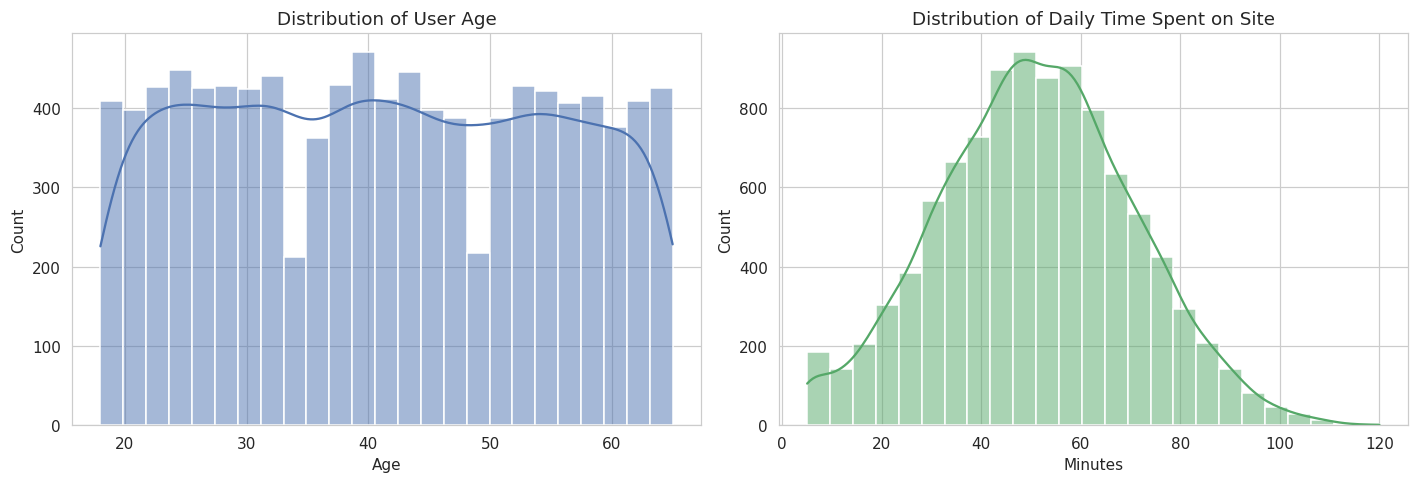

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data['Age'], bins=25, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Distribution of User Age")
axes[0].set_xlabel("Age")

sns.histplot(data['Daily_Time_Spent_on_Site'], bins=25, kde=True, color="#55A868", ax=axes[1])
axes[1].set_title("Distribution of Daily Time Spent on Site")
axes[1].set_xlabel("Minutes")

plt.tight_layout()
plt.show()

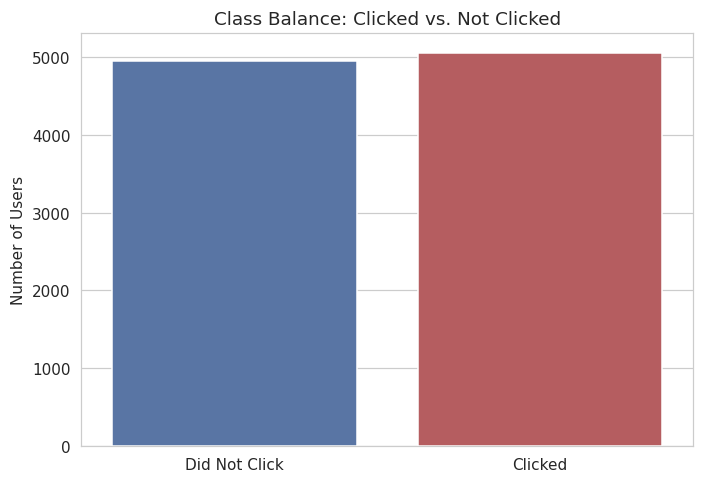

Click rate: 50.5 %


In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.countplot(data=data, x='Clicked', hue='Clicked', palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Did Not Click', 'Clicked'])
ax.set_title("Class Balance: Clicked vs. Not Clicked")
ax.set_xlabel("")
ax.set_ylabel("Number of Users")
plt.tight_layout()
plt.show()

print("Click rate:", round(data['Clicked'].mean() * 100, 2), "%")

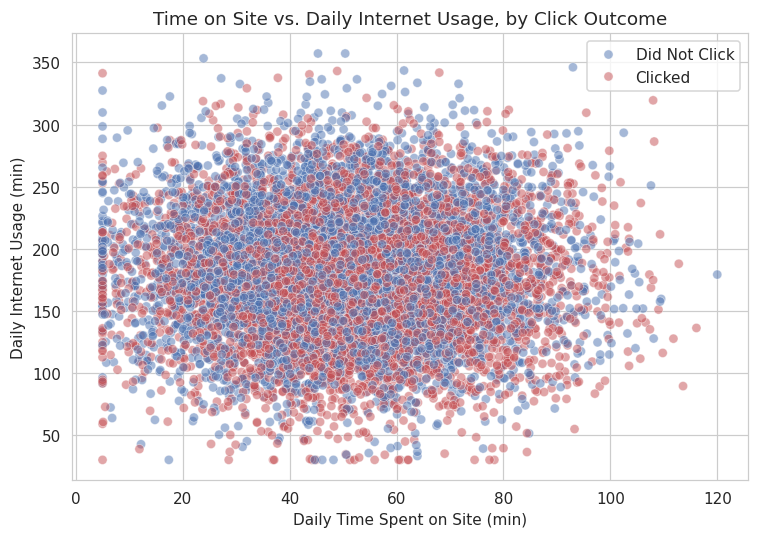

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(
    data=data, x='Daily_Time_Spent_on_Site', y='Daily_Internet_Usage',
    hue='Clicked', palette={0: "#4C72B0", 1: "#C44E52"}, alpha=0.5, ax=ax
)
ax.set_title("Time on Site vs. Daily Internet Usage, by Click Outcome")
ax.set_xlabel("Daily Time Spent on Site (min)")
ax.set_ylabel("Daily Internet Usage (min)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Did Not Click', 'Clicked'], title="")
plt.tight_layout()
plt.show()

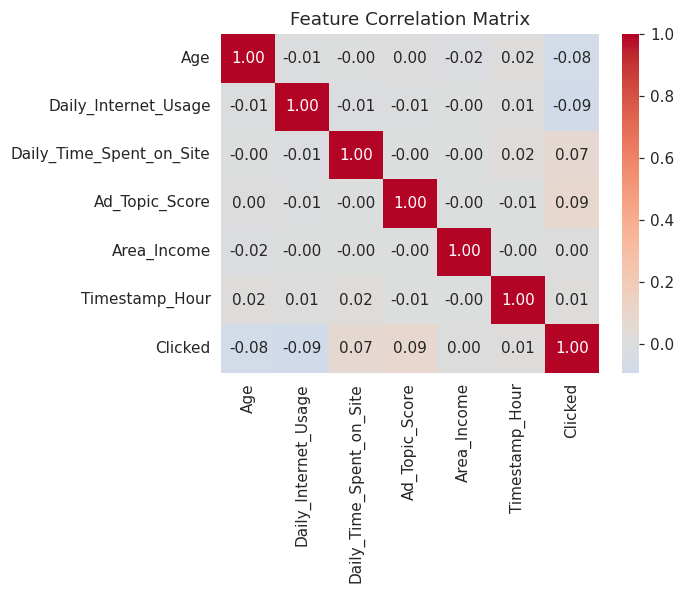

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
corr = data.drop(columns=['UserID']).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [8]:
X = data[['UserID', 'Age', 'Daily_Internet_Usage', 'Daily_Time_Spent_on_Site', 'Ad_Topic_Score', 'Area_Income', 'Timestamp_Hour']]
y = data['Clicked']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (10000, 7)
Target shape: (10000,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [12]:
y_pred = model.predict(X_test_scaled)

print("Model Evaluation:\n")
print("Accuracy:", accuracy_score(y_test, y_pred))

Model Evaluation:

Accuracy: 0.5695


### Model Evaluation

/usr/local/lib/python3.12/dist-packages/sklearn/utils/_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


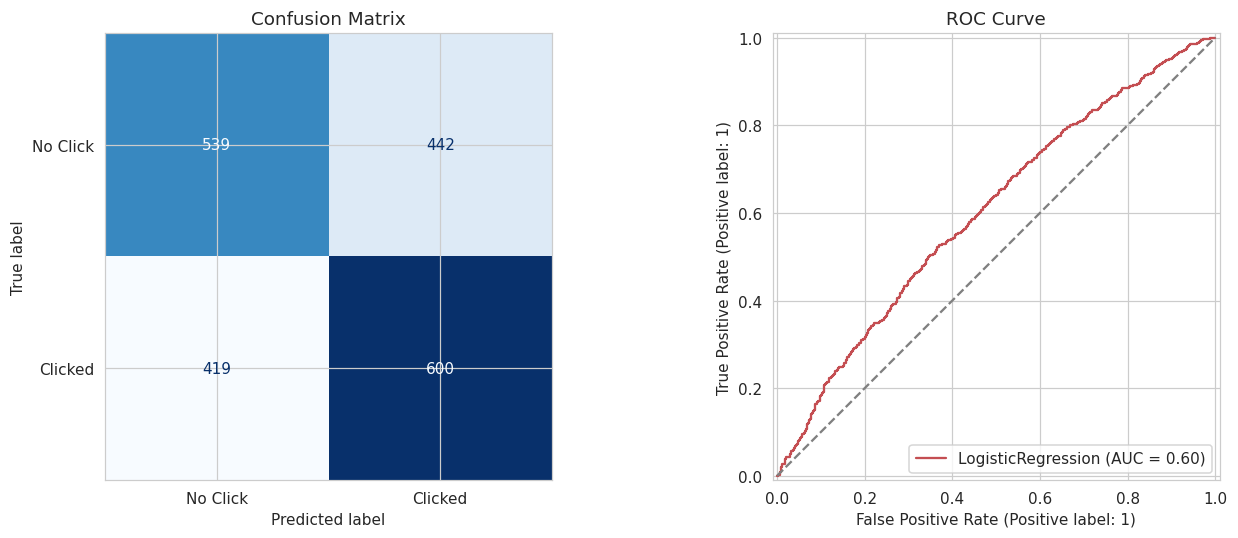

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Click', 'Clicked'])
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_estimator(model, X_test_scaled, y_test, ax=axes[1], color="#C44E52")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("ROC Curve")

plt.tight_layout()
plt.show()